# 11c — Jeux globaux : sélection d'équilibre sous information incomplète

**Navigation** : [<< 11-BayesianGames](GameTheory-11-BayesianGames-Python.ipynb) | [Index](README.md) | [12-ReputationGames >>](GameTheory-12-ReputationGames-Python.ipynb)

Un jeu de coordination a **plusieurs équilibres** : deux issues stables, et rien, dans le jeu
lui-même, pour prédire laquelle va se réaliser. Les **jeux globaux** (édifice bayésien de
Harsanyi, puis Carlsson & van Damme (1993), puis Morris & Shin (1998)) lèvent cette indétermination **sans ajouter d'arbre ni
d'action observable** : on donne aux joueurs une *information incomplète partagée* — un état
commun qu'ils ne connaissent que par un **signal bruité** (un *tremble* privé). L'équilibre de
Nash bayésien devient **unique** (tremble sous le niveau critique), et quand le tremble s'amenuise, il **sélectionne** l'issue
cohérente avec l'état fondamental.

## Ce que cet opus ajoute au palier 11

- **Réutilisation de la mécanique 11** : la pièce maîtresse est une **croyance conditionnelle**
  $\mathbb{E}[\theta \mid x]$ — exactement le calcul de Bayes que
  [11](GameTheory-11-BayesianGames-Python.ipynb) pose pour les types privés
  (`get_conditional_prob`, `compute_expected_payoff`). On le déplace ici d'un *type discret*
  vers un *état continu* observé par un signal bruité.
- **Un nouvel usage : la sélection.** [11] calcule un équilibre bayésien *donné* le jeu ;
  [10](GameTheory-10-ForwardInduction-SPE-Python.ipynb) **sélectionne** un équilibre *en forme
  extensive*, en lisant une action observée. Les jeux globaux **sélectionnent en forme normale** :
  la multiplicité se résout par la *structure des croyances* sur un état commun, pas par la
  structure arborescente. C'est l'apport spécifique de ce carnet.


## 1. Le problème : la multiplicité de la coordination

Sur un jeu de coordination, plusieurs profils d'actions sont des équilibres de Nash stables.
Sans autre information, le jeu est **indéterminé** : rien ne dit laquelle des issues stables va
se réaliser. Les jeux globaux ajoutent une broutille d'information — un état commun mal connu —
et montrent que **l'unique** équilibre qu'ils engendrent (tremble sous le niveau critique) converge, quand le bruit s'amenuise,
vers l'issue *fondamentale*.


## 2. Le modèle — un jeu de coordination perturbé

Deux agents se **coordonnent** sur l'entrée dans un projet commun. La **valeur du projet** est un
**état commun** $\theta \sim \mathcal{N}(0,1)$ que ni l'un ni l'autre ne connaît exactement.
Chacun observe un **signal privé** :

$$x_i = \theta + \varepsilon_i, \qquad \varepsilon_i \sim \mathcal{N}(0, \sigma^2)$$

le **tremble** (bruit privé de variance $\sigma^2$). Chacun choisit **Entrer (E)** ou **Rester
(O)**. Entrer rapporte $\theta - m$ si je suis seul, $\theta + m$ si l'autre entre aussi — la
coordination réussie est la plus valueuse — et rester rapporte $0$. Le gain d'entrer est donc
$\theta - m + 2m \cdot \mathbb{1}\{\text{l'autre entre}\}$ : la présence de l'autre
**renforce** mon gain d'entrer, c'est la **complémentarité stratégique** qui fait de ce jeu un
jeu de coordination (et non de congestion). Entrer ensemble est efficace quand $\theta$ est
haut, une perte quand il est bas : la coordination porte sur une décision dont la **valeur
fondamentale** est $\theta$.


In [1]:
import numpy as np
from scipy.stats import norm
import matplotlib.pyplot as plt

# --- état commun et tremble ---
m = 1.0          # bénéfice de coordination : -m si je suis seul, +m si l'autre entre
# theta ~ N(0,1) ; signal x_i = theta + eps_i, eps_i ~ N(0, sigma^2)

def mu(x, sigma):
    """E[theta | x] — croyance conditionnelle (moyenne normale)."""
    return x / (1.0 + sigma**2)

def var_theta_given_x(sigma):
    return sigma**2 / (1.0 + sigma**2)

def p_other_enters(x, c, sigma):
    """P(l'autre entre | x) = P(x_j >= c | x), sous la stratégie seuil de l'autre."""
    sd = np.sqrt(sigma**2 + var_theta_given_x(sigma))
    return norm.cdf((mu(x, sigma) - c) / sd)

def payoff_enter(x, c, sigma):
    """E[gain d'entrer | x], sachant que l'autre entre si x_j >= c.

    Coordination : entrer rapporte theta - m seul, theta + m si l'autre entre,
    soit en espérance  mu(x) - m + 2*m*P(l'autre entre | x). La complémentarité
    (+2m au terme de croyance) rend ce gain CROISSANT en x : c'est ce qui
    autorise l'équilibre de seuil.
    """
    return mu(x, sigma) - m + 2.0 * m * p_other_enters(x, c, sigma)


**Ces quatre fonctions sont le cœur bayésien** : `mu` est la croyance
$\mathbb{E}[\theta \mid x]$, `p_other_enters` est la croyance sur l'action de l'autre
conditionnelle au signal. C'est la mécanique de [11], transposée à un état continu.

La différence avec un jeu de congestion tient au **signe** du terme de croyance : ici
`+ 2m · P(l'autre entre)`, car l'entrée de l'autre **complète** la mienne (complémentarité).
Ce signe fait de `payoff_enter` une fonction **croissante** de mon signal $x$ — un signal haut
rend l'entrée plus attractive — et c'est exactement la condition pour qu'une stratégie seuil
soit un équilibre de Nash bayésien.


In [2]:
# --- l'équilibre de Nash bayésien est une stratégie seuil : entrer si x_i >= c ---
# Le joueur au signal x = c est indifférent entre entrer et rester :
#     E[theta | c]  -  m  +  2m * P(l'autre entre | c)  =  0
def indifference(c, sigma):
    return payoff_enter(c, c, sigma)

def solve_cutoff(sigma, lo=-8.0, hi=8.0):
    """Racine de l'indifférence ; bisection valide seulement là où elle est croissante.

    Contrat : renvoie le seuil BNE **unique** c*(sigma), lisible comme
    « sélection » seulement tant que l'unicité tient, c'est-à-dire tant que
    la dérivée de l'indifférence au fondamental est positive, H'(0) > 0
    (tremble **sous le niveau critique**, ~= 1.44 dans ce modèle). Au-delà,
    plusieurs racines coexistent et l'indifférence n'est plus croissante
    partout (H'(0) < 0) ; la bisection, qui suppose la croissance sur
    [lo, hi], en renvoie alors une arbitraire selon le signe aux bornes —
    elle renvoie None si aucun changement de signe n'y est vu. Le seuil
    « sélectionne » donc uniquement dans la région d'unicité ; hors d'elle,
    ce que rend cette fonction n'est pas une sélection.
    """
    Hlo, Hhi = indifference(lo, sigma), indifference(hi, sigma)
    if Hlo * Hhi > 0:
        return None
    for _ in range(200):
        mid = 0.5 * (lo + hi)
        if indifference(mid, sigma) > 0:
            hi = mid
        else:
            lo = mid
    return 0.5 * (lo + hi)

print("seuil BNE c*(sigma),  m =", m)
for s in [1.0, 0.5, 0.3, 0.1, 0.05, 0.01, 0.001]:
    print(f"  sigma={s:<7} c*={solve_cutoff(s):.4f}")

seuil BNE c*(sigma),  m = 1.0
  sigma=1.0     c*=0.0000
  sigma=0.5     c*=0.0000
  sigma=0.3     c*=0.0000
  sigma=0.1     c*=0.0000
  sigma=0.05    c*=0.0000
  sigma=0.01    c*=0.0000
  sigma=0.001   c*=0.0000


In [3]:
# --- vérification de la MEILLEURE RÉPONSE de part et d'autre du seuil ---
# Trouver une racine de l'indifférence ne suffit pas : il faut que la stratégie
# seuil soit une MEILLEURE RÉPONSE à l'autre qui joue le même seuil. On vérifie
# les deux inégalités (ce que la racine seule n'attestait pas) :
sigma = 0.1
c = solve_cutoff(sigma)
below = payoff_enter(c - 0.01, c, sigma)   # juste sous le seuil : prescrit Rester
above = payoff_enter(c + 0.01, c, sigma)   # juste au-dessus  : prescrit Entrer
# dérivée du gain en son propre signal, au seuil (doit être > 0)
deriv = (payoff_enter(c + 0.01, c, sigma) - payoff_enter(c - 0.01, c, sigma)) / 0.02
print(f"sigma={sigma},  seuil c*={c:.6f}")
print(f"  juste SOUS le seuil   : gain d'entrer = {below:+.6f}  (doit être < 0 -> rester est bien optimal)")
print(f"  juste AU-DESSUS       : gain d'entrer = {above:+.6f}  (doit être > 0 -> entrer est bien optimal)")
print(f"  dérivée du gain en x au seuil = {deriv:+.4f}  (> 0 : la meilleure réponse est croissante)")
assert below < 0 < above, "MEILLEURE RÉPONSE violée : ce n'est pas un BNE de seuil"
print("-> les deux inégalités de meilleure réponse tiennent : le seuil est bien un BNE.")


sigma=0.1,  seuil c*=0.000000
  juste SOUS le seuil   : gain d'entrer = -0.065854  (doit être < 0 -> rester est bien optimal)
  juste AU-DESSUS       : gain d'entrer = +0.065854  (doit être > 0 -> entrer est bien optimal)
  dérivée du gain en x au seuil = +6.5854  (> 0 : la meilleure réponse est croissante)
-> les deux inégalités de meilleure réponse tiennent : le seuil est bien un BNE.


La structure d'équilibre est **théoriquement** une stratégie seuil : chacun entre au-delà
d'un seuil $c^*(\sigma)$ de son signal. La résoudre, c'est trouver le signal où le joueur est
**indifférent** entre entrer et rester — une seule inconnue, une seule équation.


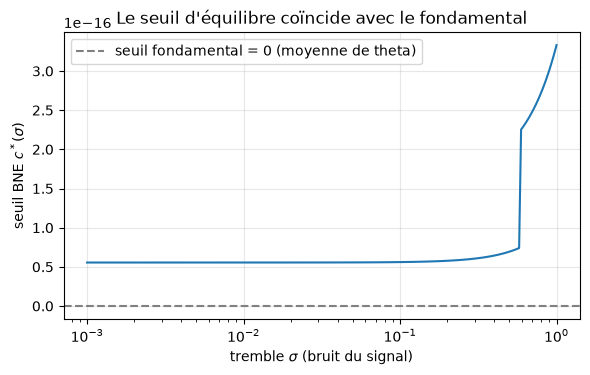

In [4]:
# --- la sélection : le seuil coïncide avec le fondamental (moyenne 0) pour tout tremble ---
sigmas = np.linspace(0.001, 1.0, 60)
cstar = np.array([solve_cutoff(s) for s in sigmas])

plt.figure(figsize=(6, 4))
plt.plot(sigmas, cstar, "-")
plt.axhline(0.0, color="grey", ls="--", label="seuil fondamental = 0 (moyenne de theta)")
plt.xscale("log")
plt.xlabel("tremble $\\sigma$ (bruit du signal)")
plt.ylabel("seuil BNE $c^*(\\sigma)$")
plt.title("Le seuil d'équilibre coïncide avec le fondamental")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


**Lecture.** Par symétrie du modèle, le seuil d'équilibre $c^*(\sigma)$ vaut exactement $0$ —
la **moyenne du fondamental** — pour tout tremble. Quand le tremble s'amenuise, l'issue
d'équilibre devient une fonction de l'état réel $\theta$ — plus des croyances subjectives.
C'est le théorème : l'équilibre unique des jeux globaux (tremble sous le niveau critique)
**sélectionne** l'issue fondamentale (coordonner quand $\theta > 0$) — une sélection
**par dominance**, dont on précisera la portée et son écart à l'efficacité juste après.

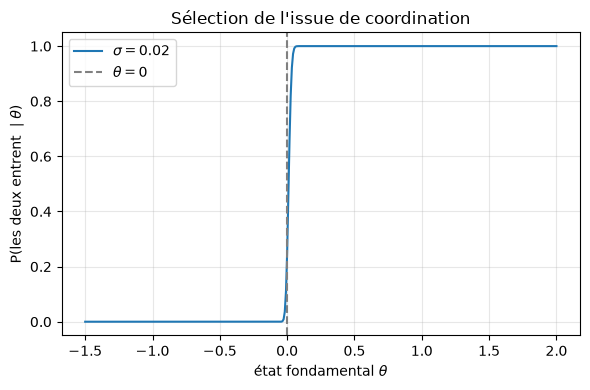

In [5]:
# --- l'issue sélectionnée : P(les deux entrent | theta) -> 1{theta > 0} ---
sigma = 0.02
c = solve_cutoff(sigma)
thetas = np.linspace(-1.5, 2.0, 400)
p_both = np.array([(1 - norm.cdf((c - t) / sigma)) ** 2 for t in thetas])

plt.figure(figsize=(6, 4))
plt.plot(thetas, p_both, label=f"$\\sigma={sigma}$")
plt.axvline(0.0, color="grey", ls="--", label="$\\theta = 0$")
plt.xlabel("état fondamental $\\theta$")
plt.ylabel("P(les deux entrent $\\mid \\theta)$")
plt.title("Sélection de l'issue de coordination")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


**Lecture.** La probabilité de **coordonner sur l'entrée** passe de 0 à 1, franchement, au
seuil fondamental $0$ (la moyenne de $\theta$). Le tremble $\to 0$ **sélectionne** coordonner
quand $\theta > 0$ — là où le jeu sans tremble laissait plusieurs issues stables. La sélection
est **lisible dans l'état**, pas dans les croyances.

Elle est une sélection **par dominance**, pas une sélection d'efficacité complète. « Entrer à
deux » **domine** « rester à deux » dès que $\theta + m > 0$, c'est-à-dire pour $\theta > -m$ :
la frontière **efficace** (Pareto) est donc en $\theta = -m$, pas en $0$. Le jeu global ne
l'atteint pas — il s'arrête à la moyenne du fondamental, $\theta = 0$. Contre-exemple, $m = 1$ :
à $\theta = -0{,}5$, entrer à deux rapporte $-0{,}5 + 1 = +0{,}5 > 0$ à chacun, donc c'est
**efficace** ; et pourtant l'équilibre sélectionné prescrit **rester** ($-0{,}5 < 0$). La
sélection par jeu global est **conservatrice** par rapport à l'efficacité : elle retient l'issue
**dominante**, pas toute la région où elle est pareto-préférable.

In [6]:
# --- unicite : une CONDITION sur le niveau de bruit, pas une loi universelle ---
# H(c) est strictement croissante au fondamental tant que sa derive en c = 0
# est positive, H'(0) > 0. On mesure cette condition pour trois trembles :
for s in (0.1, 1.0, 2.0):
    d = (indifference(0.01, s) - indifference(-0.01, s)) / 0.02
    cs = np.linspace(-6, 6, 121)
    Hv = np.array([indifference(cc, s) for cc in cs])
    nz = int(np.sum(np.diff(np.sign(Hv[Hv != 0.0])) != 0))
    verdict = "unique" if d > 0 else "multiplicite (3 seuils)"
    print(f"sigma={s:4.2f}   H'(0)={d:+.4f}   zeros de H: {nz}   ->  {verdict}")
print("-> l'equilibre est UNIQUE tant que H'(0) > 0 ; au-dela du tremble "
      "critique, la multiplicite revient.")


sigma=0.10   H'(0)=+0.9341   zeros de H: 1   ->  unique
sigma=1.00   H'(0)=+0.1743   zeros de H: 1   ->  unique
sigma=2.00   H'(0)=-0.0913   zeros de H: 3   ->  multiplicite (3 seuils)
-> l'equilibre est UNIQUE tant que H'(0) > 0 ; au-dela du tremble critique, la multiplicite revient.


**Lecture.** L'unicité n'est **pas une loi universelle** : $H(c)$ est strictement croissante au fondamental tant que sa dérivée en $0$ y est positive, $H'(0) > 0$. Pour un tremble modéré c'est le cas — un seul changement de signe, un seul seuil. Mais $H'(0)$ décroît quand le bruit grossit et **change de signe à un tremble critique** (≈ 1.44 dans ce modèle) : au-delà, la multiplicité revient (trois seuils, le central instable). Le jeu global **sélectionne** l'issue fondamentale **tant que le tremble reste sous ce niveau critique** — c'est la portée exacte du théorème, pas une unicité absolue.


## 3. Exercices


### Exercice 1 — le seuil d'équilibre

Reproduire la résolution de l'équilibre : pour un tremble donné, retourner le seuil BNE
$c^*(\sigma)$.


In [7]:
def seuil_bayesien(sigma):
    """Retourner le seuil d'équilibre c*(sigma).

    # TODO etudiant : appeler la bonne fonction du carnet ci-dessus.
    """
    return None  # TODO etudiant

# Indice : la résolution de l'indifférence est déjà écrite plus haut —
# réutilisez-la plutôt que de la réécrire.
print("Exercice à compléter :", seuil_bayesien(0.1))


Exercice à compléter : None


### Exercice 2 — la probabilité de coordination

Écrire la fonction qui, **donné** un état fondamental $\theta$, un seuil $c$ et un tremble
$\sigma$, retourne $P(\text{les deux entrent} \mid \theta)$.


In [8]:
def prob_coordonner(theta, c, sigma):
    """P(les deux entrent | theta), sachant que chacun entre si son signal >= c.

    # TODO etudiant : chaque signal x = theta + eps, avec eps ~ N(0, sigma^2).
    """
    return None  # TODO etudiant

# Indice : il faut la probabilité qu'UN signal dépasse c, puis le fait que les
# deux signaux (indépendants) le dépassent.
print("Exercice à compléter :", prob_coordonner(1.0, 0.5, 0.1))


Exercice à compléter : None


### Exercice 3 — l'effet d'un a priori décalé

Si l'état commun suit $\theta \sim \mathcal{N}(\mu_0, 1)$ au lieu de $\mathcal{N}(0,1)$, le
**fondamental** est décalé de $\mu_0$. Le seuil **sélectionné** — la frontière de dominance
au-delà de laquelle coordonner est l'issue retenue — suit-il la nouvelle moyenne $\mu_0$, ou
reste-t-il partiellement ancré ? **Mesurez** le nouveau seuil, ne supposez pas.

In [9]:
def seuil_fondamental(mu0, sigma):
    """Seuil **sélectionné** (frontière de dominance) quand theta ~ N(mu0, 1).

    Le tremble garde l'écart-type sigma, et le seuil **dépend de sigma** :
    ce n'est ni mu0, ni une constante. Rendez le seuil du bruit demandé.

    # TODO etudiant : exprimer le seuil en fonction de mu0, de sigma et de m.
    """
    return None  # TODO etudiant

# Indice : on *s'attendrait* a ce que la frontiere de dominance saute a la
# nouvelle moyenne mu0. Mais la croyance E[theta|x] n'est decalee que d'une
# FRACTION de mu0, mu0*sigma^2/(1+sigma^2) (valeur au point x=0). Recalculez
# l'indifference avec cette croyance decalee et MESUREZ le nouveau seuil.
# Deux questions distinctes, a ne pas confondre :
#   (i)  le seuil FINI au bruit sigma — c'est ce que cette fonction doit rendre ;
#   (ii) sa limite quand sigma -> 0, qui vaut 0 : le seuil ne se recentre pas
#        sur mu0, il reste ancre sur le fondamental du modele symetrique.
print("Exercice à compléter :", seuil_fondamental(0.5, 0.3))

Exercice à compléter : None


## 4. Ce que la sélection par jeu global fait que l'induction en avant ne fait pas

[10](GameTheory-10-ForwardInduction-SPE-Python.ipynb) **sélectionne** en lisant une *action
observée* dans un *arbre* : renoncer à une option extérieure est un signal sur les
intentions. La sélection par **jeu global** n'a ni arbre ni action observée : elle naît de la
*structure des croyances* sur un état commun. Deux instruments de sélection, deux logiques —
l'un temporelle (forme extensive), l'autre informationnelle (forme normale). Le jeu global est
l'outil quand la coordination est **simultanée** et que l'indétermination vient de
l'information, pas de l'ordre des coups.


### Sans région de dominance, pas de sélection

Tout ce qui précède repose sur un fait qu'on n'a pas encore mis en avant : ce jeu de
coordination **possède une région de dominance**. Pour $\theta > -m$, « entrer à deux »
**domine** « rester à deux » (chacun gagne $\theta + m > 0$ au lieu de $0$) ; c'est cette
structure de dominance qui **donne un sens** à la sélection. Sans elle — un jeu où aucune
issue n'est dominante, où les deux équilibres restent incomparables quel que soit l'état — le
tremble ne **sélectionne rien** : l'unique équilibre de Nash bayésien existe toujours, mais il
ne pointe vers aucune issue privilégiée. La sélection par jeu global n'est donc pas un effet du
bruit ; elle **lit** la région de dominance, et n'existe réellement que là où celle-ci existe
(cf. #21801).

## Références

- Carlsson, H., & van Damme, E. (1993). « Global Games and Equilibrium Selection », *Econometrica* 61(5), 989–1018. — Introduction du **jeu global** : un état tiré d'une classe de jeux, observé avec bruit par chaque joueur ; quand le bruit s'annule, l'élimination itérée des stratégies dominées sélectionne l'équilibre de **dominance de risque** (critère de Harsanyi–Selten).
- Morris, S., & Shin, H. S. (1998). « Unique Equilibrium in a Model of Self-Fulfilling Currency Attacks », *American Economic Review* 88(3), 587–597. — L'application canonique du programme de Carlsson & van Damme : un équilibre **unique** en seuil d'attaque, sélectionné par le bruit privé.

L'ordre chronologique fait foi : le concept de jeu global est dû à **Carlsson & van Damme (1993)**, qui s'appuient sur l'édifice bayésien de Harsanyi (1967–1968) ; **Morris & Shin (1998)** en ont donné l'application de référence et la popularisation.